# Data Preparation and Preprocessing

**Project:** Customer Churn Analysis for Advanced Telecommunications Solutions (ATS)
**Team:** Team 3 (WILDA26_07B)
**Prepared by:** Ravi Nagpal
**Role:** Data Engineer, Preprocessing and Feature Engineering
**Stage:** Stage 2, Deliverable 2-1 Data Preparation

This notebook covers the data preparation and preprocessing work for the customer churn dataset. It loads the supplied dataset, checks its quality, cleans the records that require treatment, encodes the categorical variables, splits the data into training and testing sets and applies scaling to the numerical features.

The prepared outputs at the end of this notebook are intended to be used directly for the K-Means clustering analysis and the ANN predictive modelling, so that all later work is based on the same version of the data.

**How to run this notebook:** place the file `Dataset_ATS_v2.csv` in the same folder as this notebook and run the cells in order from top to bottom.

## 1. Import Libraries

The libraries used in this notebook are pandas and NumPy for data handling, matplotlib and seaborn for the basic checks, and scikit-learn for the train and test split and the scaling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 42
DATA_PATH = "Dataset_ATS_v2.csv"

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The dataset is loaded from the supplied CSV file. The shape of the dataset and the first few records are displayed so that the structure can be confirmed before any further work is carried out.

In [2]:
df = pd.read_csv(DATA_PATH)

print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of records: 7043
Number of columns: 10


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gender           7043 non-null   str  
 1   SeniorCitizen    7043 non-null   int64
 2   Dependents       7043 non-null   str  
 3   tenure           7043 non-null   int64
 4   PhoneService     7043 non-null   str  
 5   MultipleLines    7043 non-null   str  
 6   InternetService  7043 non-null   str  
 7   Contract         7043 non-null   str  
 8   MonthlyCharges   7043 non-null   int64
 9   Churn            7043 non-null   str  
dtypes: int64(3), str(7)
memory usage: 550.4 KB


## 3. Data Quality Checks

Before any cleaning is applied, the dataset is checked for missing values, duplicate records, unusual values and the balance of the target variable. The results of these checks determine which treatments are required.

### 3.1 Missing Values

In [4]:
missing = df.isnull().sum()
print("Total missing values in the dataset:", missing.sum())
missing

Total missing values in the dataset: 0


gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64

There are no missing values in any column. Missing data is therefore not a quality issue for this dataset, and no imputation is required.

### 3.2 Duplicate Records

In [5]:
duplicate_count = df.duplicated().sum()
print("Number of exact duplicate rows:", duplicate_count)
print("Percentage of the dataset:", round(duplicate_count / len(df) * 100, 2), "%")

df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Number of exact duplicate rows: 302
Percentage of the dataset: 4.29 %


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1539,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1907,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
3227,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
5085,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
6531,Female,0,No,1,Yes,No,DSL,Month-to-month,20,No
752,Female,0,No,1,Yes,No,DSL,Month-to-month,20,Yes
4470,Female,0,No,1,Yes,No,DSL,Month-to-month,20,Yes
3507,Female,0,No,1,Yes,No,DSL,Month-to-month,21,No
4262,Female,0,No,1,Yes,No,DSL,Month-to-month,21,No


There are 302 exact duplicate rows, which is around 4.3% of the dataset. The dataset does not contain a customer identifier, so it is not possible to confirm whether these records represent genuinely repeated customers or data-entry duplicates. The duplicates are removed in the cleaning step because retaining them would give additional weight to those records in both the clustering and the predictive modelling.

### 3.3 Unusual Values in the Numerical Columns

In [6]:
df[["tenure", "MonthlyCharges", "SeniorCitizen"]].describe()

,tenure,MonthlyCharges,SeniorCitizen
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.758768,0.162147
std,24.559481,30.091650,0.368612
min,0.000000,18.000000,0.000000
25%,9.000000,36.000000,0.000000
50%,29.000000,70.000000,0.000000
75%,55.000000,90.000000,0.000000
max,72.000000,119.000000,1.000000


In [7]:
zero_tenure = df[df["tenure"] == 0]
print("Records with a tenure of zero months:", len(zero_tenure))
zero_tenure.head()

Records with a tenure of zero months: 11


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
765,Female,0,Yes,0,Yes,No,DSL,Month-to-month,73,No
1413,Male,0,Yes,0,Yes,Yes,Fiber optic,Two year,62,No
1691,Female,0,Yes,0,No,No,DSL,Two year,56,No
3828,Male,0,Yes,0,Yes,No,DSL,Two year,25,No
4143,Male,0,Yes,0,Yes,Yes,Fiber optic,Month-to-month,20,No


Tenure ranges from 0 to 72 months and 11 records have a tenure of zero months. These records appear to represent new customers who have not yet completed a full month of service. They are retained in the dataset and marked with an indicator column so that they can be identified during the analysis, because removing them would remove a group of customers that may behave differently from the rest.

MonthlyCharges ranges from 18 to 119 and the values are recorded only in whole dollars. This suggests that the source data was rounded before it was provided, so the values are treated as an approximate measure.

### 3.4 Balance of the Target Variable

In [8]:
churn_counts = df["Churn"].value_counts()
churn_percent = df["Churn"].value_counts(normalize=True) * 100

summary = pd.DataFrame({"Count": churn_counts, "Percentage": churn_percent.round(1)})
summary

,Count,Percentage
Churn,,
No,5174,73.5
Yes,1869,26.5


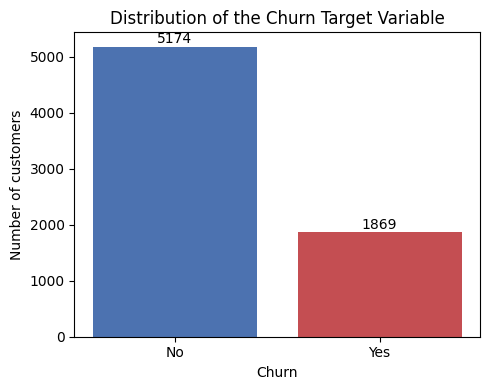

In [9]:
plt.figure(figsize=(5, 4))
plt.bar(churn_counts.index, churn_counts.values, color=["#4C72B0", "#C44E52"])
plt.title("Distribution of the Churn Target Variable")
plt.ylabel("Number of customers")
plt.xlabel("Churn")
for i, v in enumerate(churn_counts.values):
    plt.text(i, v + 60, str(v), ha="center")
plt.tight_layout()
plt.show()

There are 1,869 customers who churned, representing 26.5% of the dataset, and 5,174 customers who were retained, representing 73.5%. This is a noticeable class imbalance. A model trained on this data could report an accuracy of around 73% while failing to identify the customers who actually churn. For this reason the train and test split is stratified on the target variable, and the modelling stage should assess performance using recall, precision, F1 and ROC-AUC rather than accuracy alone.

## 4. Data Cleaning

Two treatments are applied in this section. The duplicate records are removed and an indicator column is added for the customers with a tenure of zero months. The row count is recorded before and after cleaning so that the team can confirm that they are working from the same version of the data.

In [10]:
rows_before = len(df)

df_clean = df.drop_duplicates().reset_index(drop=True)

rows_after = len(df_clean)

print("Rows before cleaning:", rows_before)
print("Rows removed:", rows_before - rows_after)
print("Rows after cleaning:", rows_after)

Rows before cleaning: 7043
Rows removed: 302
Rows after cleaning: 6741


In [11]:
df_clean["new_customer"] = (df_clean["tenure"] == 0).astype(int)

print("Records marked as new customers:", df_clean["new_customer"].sum())
df_clean.head()

Records marked as new customers: 11


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn,new_customer
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes,0
1,Male,0,No,41,Yes,No,DSL,One year,25,No,0
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No,0
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes,0
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No,0


## 5. Encoding the Categorical Variables

The categorical variables are converted into a numerical form so that they can be used by the clustering and modelling algorithms.

The binary variables are mapped to 0 and 1. The variables with more than two categories are converted using one-hot encoding, with the first category dropped to avoid creating redundant columns. The target variable is mapped separately so that a churned customer is represented by 1.

In [12]:
df_encoded = df_clean.copy()

binary_map = {"Yes": 1, "No": 0, "Male": 1, "Female": 0}
binary_columns = ["gender", "Dependents", "PhoneService", "MultipleLines"]

for column in binary_columns:
    df_encoded[column] = df_encoded[column].map(binary_map)

df_encoded["Churn"] = df_encoded["Churn"].map({"Yes": 1, "No": 0})

print("Binary variables encoded.")
df_encoded[binary_columns + ["Churn"]].head()

Binary variables encoded.


,gender,Dependents,PhoneService,MultipleLines,Churn
0,0,0,0,0,1
1,1,0,1,0,0
2,0,1,1,0,0
3,0,0,1,0,1
4,1,0,1,0,0


In [13]:
multi_category_columns = ["InternetService", "Contract"]

df_encoded = pd.get_dummies(df_encoded, columns=multi_category_columns, drop_first=True, dtype=int)

print("Columns after encoding:", df_encoded.shape[1])
df_encoded.head()

Columns after encoding: 12


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,Churn,new_customer,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,1,0,0,25,1,0,0,0,0
1,1,0,0,41,1,0,25,0,0,0,1,0
2,0,0,1,52,1,0,19,0,0,0,0,0
3,0,0,0,1,1,0,76,1,0,0,1,0
4,1,0,0,67,1,0,51,0,0,1,0,0


In [14]:
assert df_encoded.isnull().sum().sum() == 0, "Encoding has produced missing values."
assert all(df_encoded.dtypes != "object"), "A text column remains in the dataset."

print("All variables are now numerical and no missing values were introduced.")
df_encoded.dtypes

All variables are now numerical and no missing values were introduced.


gender                         int64
SeniorCitizen                  int64
Dependents                     int64
tenure                         int64
PhoneService                   int64
MultipleLines                  int64
MonthlyCharges                 int64
Churn                          int64
new_customer                   int64
InternetService_Fiber optic    int64
Contract_One year              int64
Contract_Two year              int64
dtype: object

## 6. Train and Test Split

The dataset is separated into the input features and the target variable, and then split into a training set and a testing set. An 80/20 split is used and the split is stratified on the target variable so that the proportion of churned customers is the same in both sets.

The split is carried out before the scaling is applied. This is done to prevent data leakage, because fitting a scaler on the full dataset would allow information from the testing set to influence the values used for training.

In [15]:
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape[0], "records")
print("Testing set:", X_test.shape[0], "records")
print("Number of features:", X_train.shape[1])
print()
print("Churn rate in the training set:", round(y_train.mean() * 100, 1), "%")
print("Churn rate in the testing set:", round(y_test.mean() * 100, 1), "%")

Training set: 5392 records
Testing set: 1349 records
Number of features: 11

Churn rate in the training set: 26.6 %
Churn rate in the testing set: 26.5 %


## 7. Feature Scaling

The numerical variables tenure and MonthlyCharges are measured on different scales, which would affect any method based on distance, including K-Means clustering, as well as the training of the ANN model. Standard scaling is applied so that these variables have a mean of zero and a standard deviation of one.

The scaler is fitted on the training set only and is then applied to the testing set. The already encoded binary and one-hot columns are left unchanged because they are on a 0 to 1 scale.

In [16]:
numeric_features = ["tenure", "MonthlyCharges"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print("Scaler fitted on the training set only.")
print()
print("Training set after scaling:")
print(X_train_scaled[numeric_features].describe().round(3))

Scaler fitted on the training set only.

Training set after scaling:
         tenure  MonthlyCharges
count  5392.000        5392.000
mean     -0.000           0.000
std       1.000           1.000
min      -1.359          -1.618
25%      -0.947          -0.809
50%      -0.125           0.170
75%       0.945           0.811
max       1.603           1.790


## 8. Prepared Dataset for Clustering

The clustering analysis is carried out on the full cleaned dataset rather than on the training set, because customer segmentation does not require a train and test split. A separate scaled version of the complete feature set is therefore prepared for that purpose.

In [17]:
cluster_scaler = StandardScaler()

X_cluster = X.copy()
X_cluster[numeric_features] = cluster_scaler.fit_transform(X[numeric_features])

print("Cluster-ready dataset:", X_cluster.shape[0], "records and", X_cluster.shape[1], "features")
X_cluster.head()

Cluster-ready dataset: 6741 records and 11 features


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,MonthlyCharges,new_customer,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,-1.312875,0,0,-1.376228,0,0,0,0
1,1,0,0,0.331038,1,0,-1.376228,0,0,1,0
2,0,0,1,0.783114,1,0,-1.578399,0,0,0,0
3,0,0,0,-1.312875,1,0,0.342225,0,0,1,0
4,1,0,0,1.399582,1,0,-0.500154,0,1,0,0


## 9. Export the Prepared Files

The prepared files are exported so that the clustering and modelling work can begin directly from them. The files are shared with the team together with this notebook.

| File | Purpose | Used by |
|---|---|---|
| `ATS_clean_v1.csv` | Cleaned and encoded dataset, unscaled | Reference and business analysis |
| `ATS_cluster_ready_v1.csv` | Scaled feature set for segmentation | K-Means clustering |
| `ATS_train_features_v1.csv` and `ATS_train_target_v1.csv` | Scaled training data | ANN predictive modelling |
| `ATS_test_features_v1.csv` and `ATS_test_target_v1.csv` | Scaled testing data | ANN predictive modelling |

In [18]:
df_encoded.to_csv("ATS_clean_v1.csv", index=False)
X_cluster.to_csv("ATS_cluster_ready_v1.csv", index=False)

X_train_scaled.to_csv("ATS_train_features_v1.csv", index=False)
X_test_scaled.to_csv("ATS_test_features_v1.csv", index=False)
y_train.to_csv("ATS_train_target_v1.csv", index=False)
y_test.to_csv("ATS_test_target_v1.csv", index=False)

print("All prepared files have been exported.")

All prepared files have been exported.


## 10. Summary of the Preparation Work

The table below records what was found in the dataset and the treatment that was applied. It is included so that the decisions taken during preprocessing can be explained as limitations in the final report.

In [19]:
summary_table = pd.DataFrame([
    ["Records supplied", rows_before, "Original dataset as provided"],
    ["Duplicate rows removed", rows_before - rows_after, "Exact duplicates across all columns"],
    ["Records retained", rows_after, "Used for all later analysis"],
    ["Missing values", 0, "No imputation required"],
    ["Zero-tenure records", int(df_clean["new_customer"].sum()), "Retained and marked with an indicator column"],
    ["Features after encoding", X.shape[1], "Binary mapping and one-hot encoding applied"],
    ["Training records", X_train.shape[0], "80% of the cleaned dataset, stratified"],
    ["Testing records", X_test.shape[0], "20% of the cleaned dataset, stratified"],
    ["Churn rate", str(round(y.mean() * 100, 1)) + " %", "Class imbalance to be handled during modelling"],
], columns=["Item", "Value", "Comment"])

summary_table

,Item,Value,Comment
0,Records supplied,7043,Original dataset as provided
1,Duplicate rows removed,302,Exact duplicates across all columns
2,Records retained,6741,Used for all later analysis
3,Missing values,0,No imputation required
4,Zero-tenure records,11,Retained and marked with an indicator column
5,Features after encoding,11,Binary mapping and one-hot encoding applied
6,Training records,5392,"80% of the cleaned dataset, stratified"
7,Testing records,1349,"20% of the cleaned dataset, stratified"
8,Churn rate,26.6 %,Class imbalance to be handled during modelling


## 11. Notes for the Team

The following points should be considered by the team members who will use these files.

For the clustering analysis, the file `ATS_cluster_ready_v1.csv` should be used. The features are already encoded and scaled, so the Elbow Method can be applied directly to determine the optimal number of clusters.

For the predictive modelling, the four training and testing files should be used. The scaling has been fitted on the training data only, so no further scaling should be applied. The class imbalance of 26.5% should be handled through class weighting or resampling on the training data only, and the model should be assessed using recall, precision, F1 and ROC-AUC rather than accuracy alone.

Two decisions taken during preprocessing should be confirmed by the team. The first is the removal of the 302 duplicate records, which was necessary because the dataset does not contain a customer identifier. The second is the treatment of the 11 records with a tenure of zero months, which have been retained and marked rather than removed. Both decisions should be recorded in the project documentation so that they can be reported as limitations in the final report.